## Task 1: Data Forensics & Cleaning

### 1.1 Load and Inspect

In [256]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv('pima_modified.csv')
raw_df = pd.read_csv('pima_modified.csv')

In [257]:
display(df.head(10)) # displays the first 10 rows of the dataframe

,preg,plas,pres,skin,test,mass,pedi,age,class,hospital_id
0,6,980,58,?,?,34.0,0.430,43,0,958379
1,2,1120,75,?,0,35.7,0.148,21,0,621608
2,2,1080,64,?,0,30.8,0.158,21,0,830265
3,8,1070,80,?,?,24.6,0.856,34,0,924143
4,7,1360,90,?,0,29.9,0.210,50,0,995331
5,6,1030,72,?,190,37.7,0.324,55,0,212990
6,1,710,48,?,76,20.4,0.323,22,0,769416
7,0,1170,0,?,?,33.8,0.932,44,0,382017
8,4,1540,?,?,126,31.3,0.338,37,0,229350
9,5,1470,78,?,0,33.7,0.218,65,0,652370


In [258]:
print(df.shape) # displays the number of rows and columns in the dataframe

(768, 10)


In [259]:
print(df.dtypes) # displays the data types of each column in the dataframe

preg             int64
plas             int64
pres               str
skin               str
test               str
mass           float64
pedi           float64
age              int64
class            int64
hospital_id      int64
dtype: object


### 1.2 Missing Value Investigation

In [260]:
print((df == '?').sum()) # displays the number of occurrences of '?' in each column
df = df.replace('?', np.nan) # convert ? to NaN
for col in ['pres', 'skin', 'test']:
    df[col] = pd.to_numeric(df[col])
print(df.isna().sum())
print(df[['pres', 'skin', 'test']].isna().mean() * 100) # displays the percentage of missing values per affected column

print("--------------------------------")
print(
    df[["pres", "skin", "test"]].isna().all(axis=1).sum()
)  # returns 0: no rows have all three columns as NaN
print("--------------------------------")
print(
    df[["pres", "skin", "test"]].isna().any(axis=1).sum()
)  # returns 108: 108 rows have at least one of the three columns as NaN

preg            0
plas            0
pres           38
skin           38
test           38
mass            0
pedi            0
age             0
class           0
hospital_id     0
dtype: int64
preg            0
plas            0
pres           38
skin           38
test           38
mass            0
pedi            0
age             0
class           0
hospital_id     0
dtype: int64
pres    4.947917
skin    4.947917
test    4.947917
dtype: float64
--------------------------------
0
--------------------------------
108


#### Imputation Strategy

From the code ran above it can be noticed that columns: 'pres', 'skin', 'test' contain missing values ('?'). All three contain 38/768 missing values which is approximately 4.95% of the entire column. Running the `.isna().all()` and `.isna.any()` codes also showed that the missing values are not all in the same row and are instead, scattered across different rows.

Based on this, it will be better to impute the missing values rather drop entire rows as that would result in losing a lot of data (108 out of 768 rows is a significant amount). Imputing will also be better because only approximately 5% of the columns 'pres', 'skin', and 'test' are missing values. Which means that the majority of the data is still valid and available for analysis and modelling. It also wouldn't be reasonable to drop the entire columns as 'pres' (diastolic blood pressure), 'skin' (tricep skinfold thickness), and 'test' (insulin test) are all important features in diabetes prediction. Since it's also just a few columns in the rows that are missing, it will be better to impute the missing values rather than the entire row as other columns in those rows still contain valuable information that can be used for analysis and modelling.

There are different methods of replacing missing values in a dataset:
- **Mean, median, or mode imputation**: the missing numerical values are replaced with the column's mean or median, and categorical values are replaced with mode.
- **Fixed value / constant imputation**: the missing values are replaced with a predetermined constant. Should be used when the absence of a value carries an actual meaning
- **Forward fill / backward fill**: propagates the last known value forward or the next known value backward (strictly used for time-series data).
- **Multiple imputation**: generates multiple complete datasets by estimating missing values multiple times with random variation, analyses each dataset separately, and pools the results using Rubin's rules. The standard for research and clinical datasets under Missing at Random mechanism; it accurately reflects uncertainty and prevents false-positive confidence intervals.

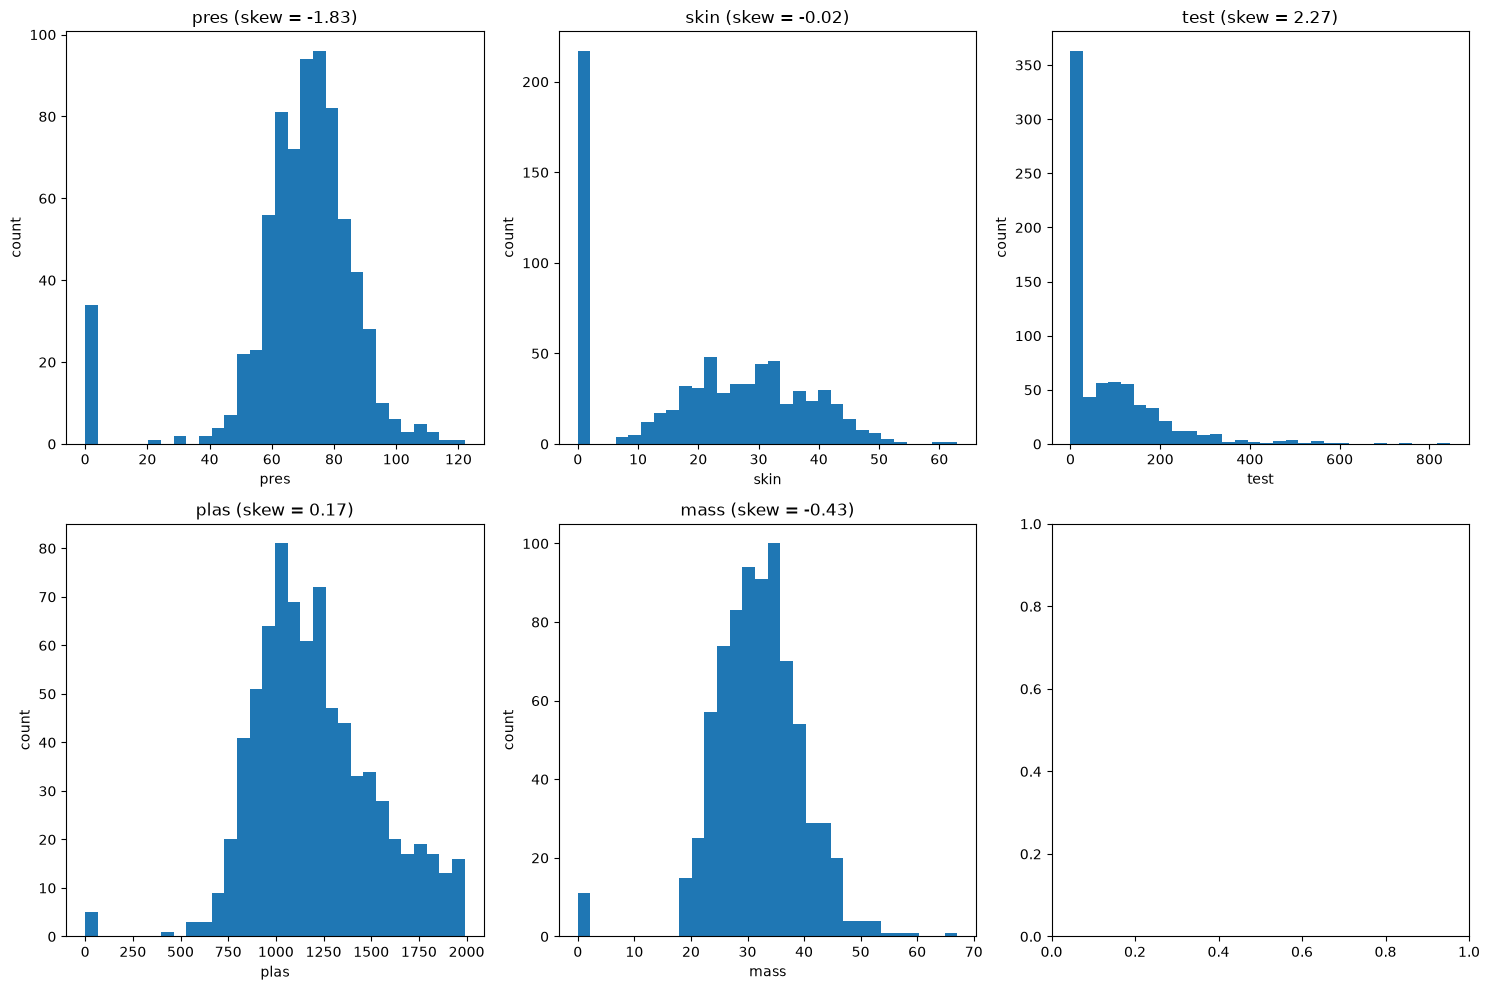

pres mean = 69.01506849315068
pres median = 72.0
skin mean = 20.346575342465755
skin median = 23.0
test mean = 80.31095890410958
test median = 34.0
plas mean = 1208.9453125
plas median = 1170.0
mass mean = 31.992578124999998
mass median = 32.0
plas      5
pres     34
skin    217
test    354
mass     11
dtype: int64
----------------------------------------------------------------
after replacing 0 with NaN


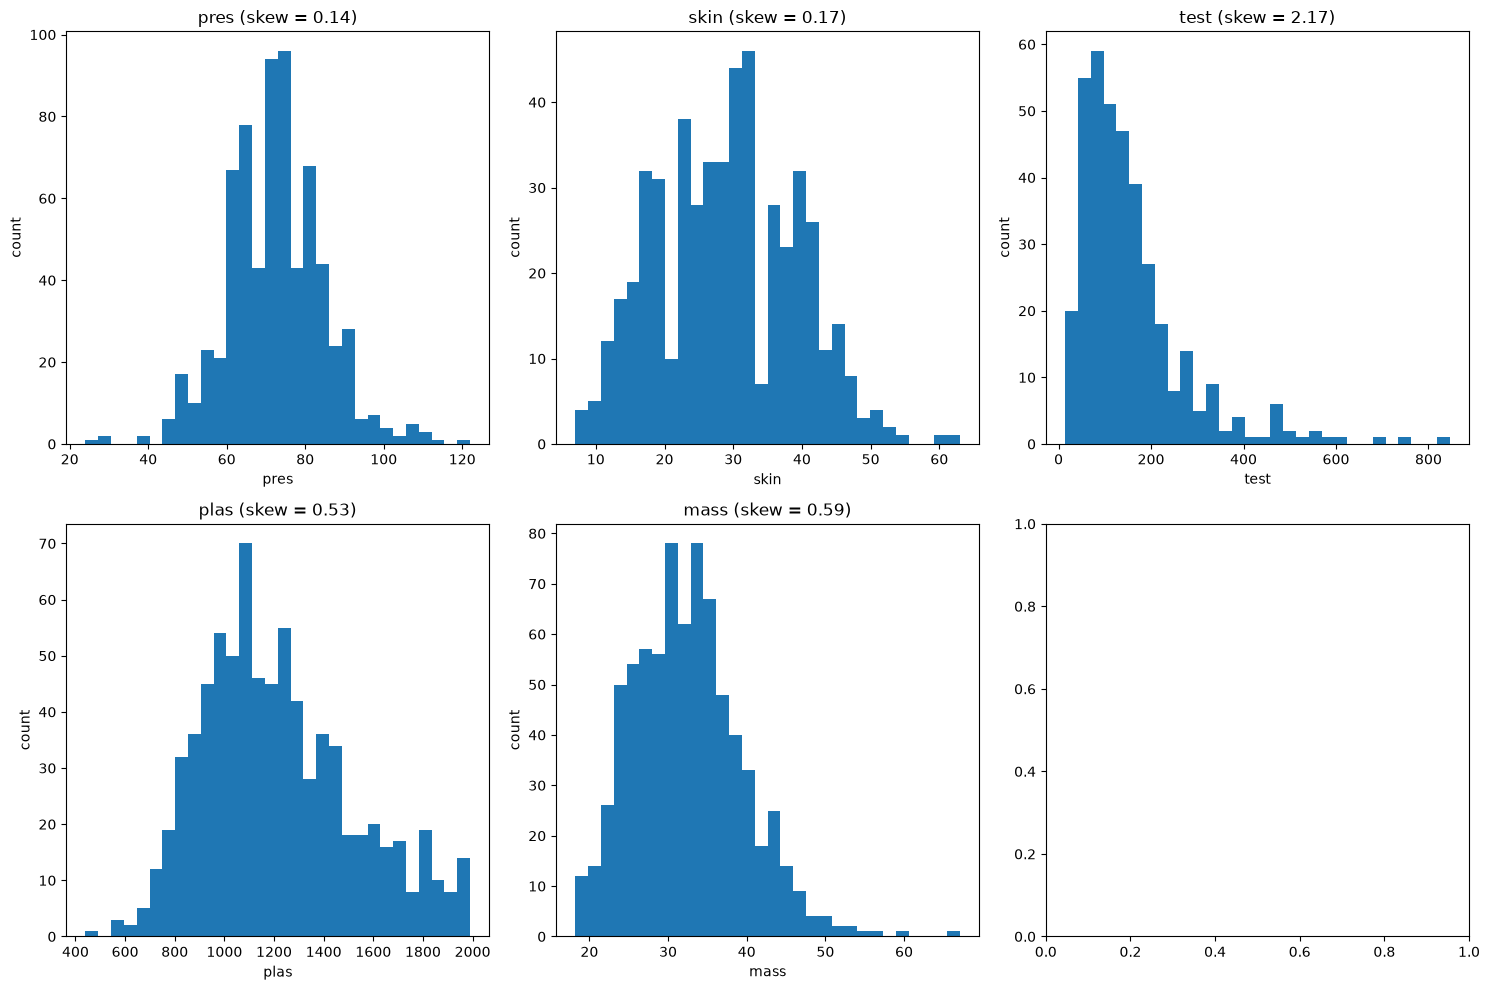

pres mean = 72.38649425287356
pres median = 72.0
skin mean = 28.953216374269005
skin median = 29.0
test mean = 155.92287234042553
test median = 125.0
plas mean = 1216.867627785059
plas median = 1170.0
mass mean = 32.457463672391015
mass median = 32.3
pres    0
skin    0
test    0
plas    0
mass    0
dtype: int64


In [261]:
cols = ['pres', 'skin', 'test', 'plas', 'mass']

fig, axes = plt.subplots(2, 3, figsize=(15, 10)) 

for ax, col in zip(axes.flatten(), cols):
    ax.hist(df[col].dropna(), bins=30) # dropna() is used to ignore NaN values in the histogram; histograms can't plot NaN values
    ax.set_title(f"{col} (skew = {df[col].skew():.2f})")
    ax.set_xlabel(col)
    ax.set_ylabel('count')

plt.tight_layout()
plt.show()

print(f"pres mean = {df.pres.mean()}")
print(f"pres median = {df.pres.median()}")

print(f"skin mean = {df.skin.mean()}")
print(f"skin median = {df.skin.median()}")

print(f"test mean = {df.test.mean()}")
print(f"test median = {df.test.median()}")

print(f"plas mean = {df.plas.mean()}")
print(f"plas median = {df.plas.median()}")

print(f"mass mean = {df.mass.mean()}")
print(f"mass median = {df.mass.median()}")

print((df[['plas', 'pres', 'skin', 'test', 'mass']] == 0).sum())

print('----------------------------------------------------------------')
print('after replacing 0 with NaN')

tmp = df[cols].replace(0, np.nan)

fig, axes = plt.subplots(2, 3, figsize=(15, 10))

for ax, col in zip(axes.flatten(), cols):
    ax.hist(
        tmp[col].dropna(), bins=30
    )  # dropna() is used to ignore NaN values in the histogram; histograms can't plot NaN values
    ax.set_title(f"{col} (skew = {tmp[col].skew():.2f})")
    ax.set_xlabel(col)
    ax.set_ylabel("count")

plt.tight_layout()
plt.show()

print(f"pres mean = {tmp.pres.mean()}")
print(f"pres median = {tmp.pres.median()}")

print(f"skin mean = {tmp.skin.mean()}")
print(f"skin median = {tmp.skin.median()}")

print(f"test mean = {tmp.test.mean()}")
print(f"test median = {tmp.test.median()}")

print(f"plas mean = {tmp.plas.mean()}")
print(f"plas median = {tmp.plas.median()}")

print(f"mass mean = {tmp.mass.mean()}")
print(f"mass median = {tmp.mass.median()}")

print((tmp == 0).sum())

According to the histogram plotted above, it can be noticed that 'pres' is significantly negatively skewed (-1.83); 'skin' has an approximately symmetric distribution (-0.02); 'test' is significantly positively skewed (2.27); 'plas' has an approximately symmetric distribution (0.17); 'mass' has an approximately symmetric distribution (-0.43).  

There is an odd behaviour that can be noticed though: 'pres' which represents blood pressure is negatively skewed. Blood pressure is usually approximately normal because it is determined by the cumulative effect of hundreds of independent genetic, environmental, and physiological variables balancing each other out across a population. The reason why it is negatively skewed here is because of the number of zeroes in the readings that represent missing values which significantly drags the tail to the left. When these zeroes were converted to NaN and left out of the distribution, 'pres' returned a skew value of 0.14 which indicates that it's approximately symmetrical and further proves the fact that it was negatively-skewed due to the zeroes in the readings.  

'test' (insulin) matches it natural behaviour of being positively skewed because when looking at the general population, while most people cluster around a lower, baseline level of insulin, a smaller subset of the population stretches out into a long tail of exceptionally high values.


All values of zeroes for 'pres', 'skin', 'test', 'plas', and 'mass', in the dataset were converted to NaN. The zeroes will be excluded when computing the statistics in all five columns, but only the zeroes in 'plas', 'pres', and 'mass' will be filled. The skew remained the same for 'skin' (approximately symmetrical) and 'test' (positively skewed). The rest had changes though: 'pres' became approximately symmetrical. 'plas' and 'mass' became positively-skewed (0.17 to 0.53 and -0.43 to 0.59 respectively) because initially a few zeroes sat about 4 standard deviations from the mean and distorted the skew.


Medically the attributes represent the following:
| Attribute | Medical meaning |
| -------- | ------- |
| preg | Pregnancies |
| plas | Plasma Glucose |
| pres | Diastolic blood pressure |
| skin | triceps skinfold thickness |
| test | 2-hour serum insulin |
| mass | Body Mass Index |
| pedi | Pedigree Function |
| age | Age |
| class | Class/Diagnosis |


To determine the imputation strategy to be used, different strategies were considered.
- *Fixed value fill imputation* is used when absence of a value has a meaning. For instance, a skipped survey question.
- *Forward/Backward fill* is strictly used for time-series data, hence, making it unsuitable in this scenario.
- *KNN and regression imputation* are both valid but are impractical for this case without sklearn as only Pandas and Matplotlib are allowed for the task.
- *Multiple imputation* is complex to implement and is used for statistical inference where you pool several analysis to get honest uncertainty.
- *Mean, median, or mode imputation* would be best suited for this scenario because of its simplicity and ease of understanding. Mean and median imputations to be more specific since they are used for numerical data and mode is used for categorical data.


Using the mean or median imputation, a mixture of them would be used for the columns. Mean imputation will be used for 'pres' and 'skin' as they are approximately symmetrical which means the mean would be an appropriate representation of the column. Median imputation will be used for 'test' because it is significantly positively skewed and using the mean would make the imputed values artificially high. For the remaining two columns: 'plas' and 'mass', median imputation will also be used cause they are also positively-skewed with skewness of 0.53 and 0.59 respectively.

Furthermore, for the columns 'plas', 'pres', and 'mass', the zeroes in the columns will be treated as missing values and imputed with selected statistics. These columns contain 5 (under 1%), 34 (about 4.4%), 11 (about 1.4%) amount of zeroes respectively which are tiny amount of zeroes. As for 'skin' and 'test', the zeroes wouldn't be imputed as the columns contain a large amount of zeroes: 217 (about 28%) and 354 (about 46%) respectively and imputing them would mean a third to half of each column would become one repeated constant, squashing the column's variation.

In [262]:
df["pres"] = df["pres"].replace(0, np.nan)
fill_value = df["pres"].mean()
df["pres"] = df["pres"].fillna(fill_value)
print(df["pres"].isna().sum())
print((df["pres"] == 0).sum())

fill_value = df["skin"].replace(0, np.nan).mean()
df["skin"] = df["skin"].fillna(fill_value)

fill_value = df["test"].replace(0, np.nan).median()
df["test"] = df["test"].fillna(fill_value)

df["plas"] = df["plas"].replace(0, np.nan)
fill_value = df["plas"].median()
df["plas"] = df["plas"].fillna(fill_value)

df["mass"] = df["mass"].replace(0, np.nan)
fill_value = df["mass"].median()
df["mass"] = df["mass"].fillna(fill_value)

0
0


In [263]:
print(df.isna().sum())
print(df["class"].value_counts())
print((df[["plas", "pres", "skin", "test", "mass"]] == 0).sum())

preg           0
plas           0
pres           0
skin           0
test           0
mass           0
pedi           0
age            0
class          0
hospital_id    0
dtype: int64
class
0    500
1    268
Name: count, dtype: int64
plas      0
pres      0
skin    217
test    354
mass      0
dtype: int64


count     768.000000
mean     1208.945312
std       319.726182
min         0.000000
25%       990.000000
50%      1170.000000
75%      1402.500000
max      1990.000000
Name: plas, dtype: float64
--------------------------
count     768.000000
mean     1216.562500
std       304.382858
min       440.000000
25%       997.500000
50%      1170.000000
75%      1402.500000
max      1990.000000
Name: plas, dtype: float64


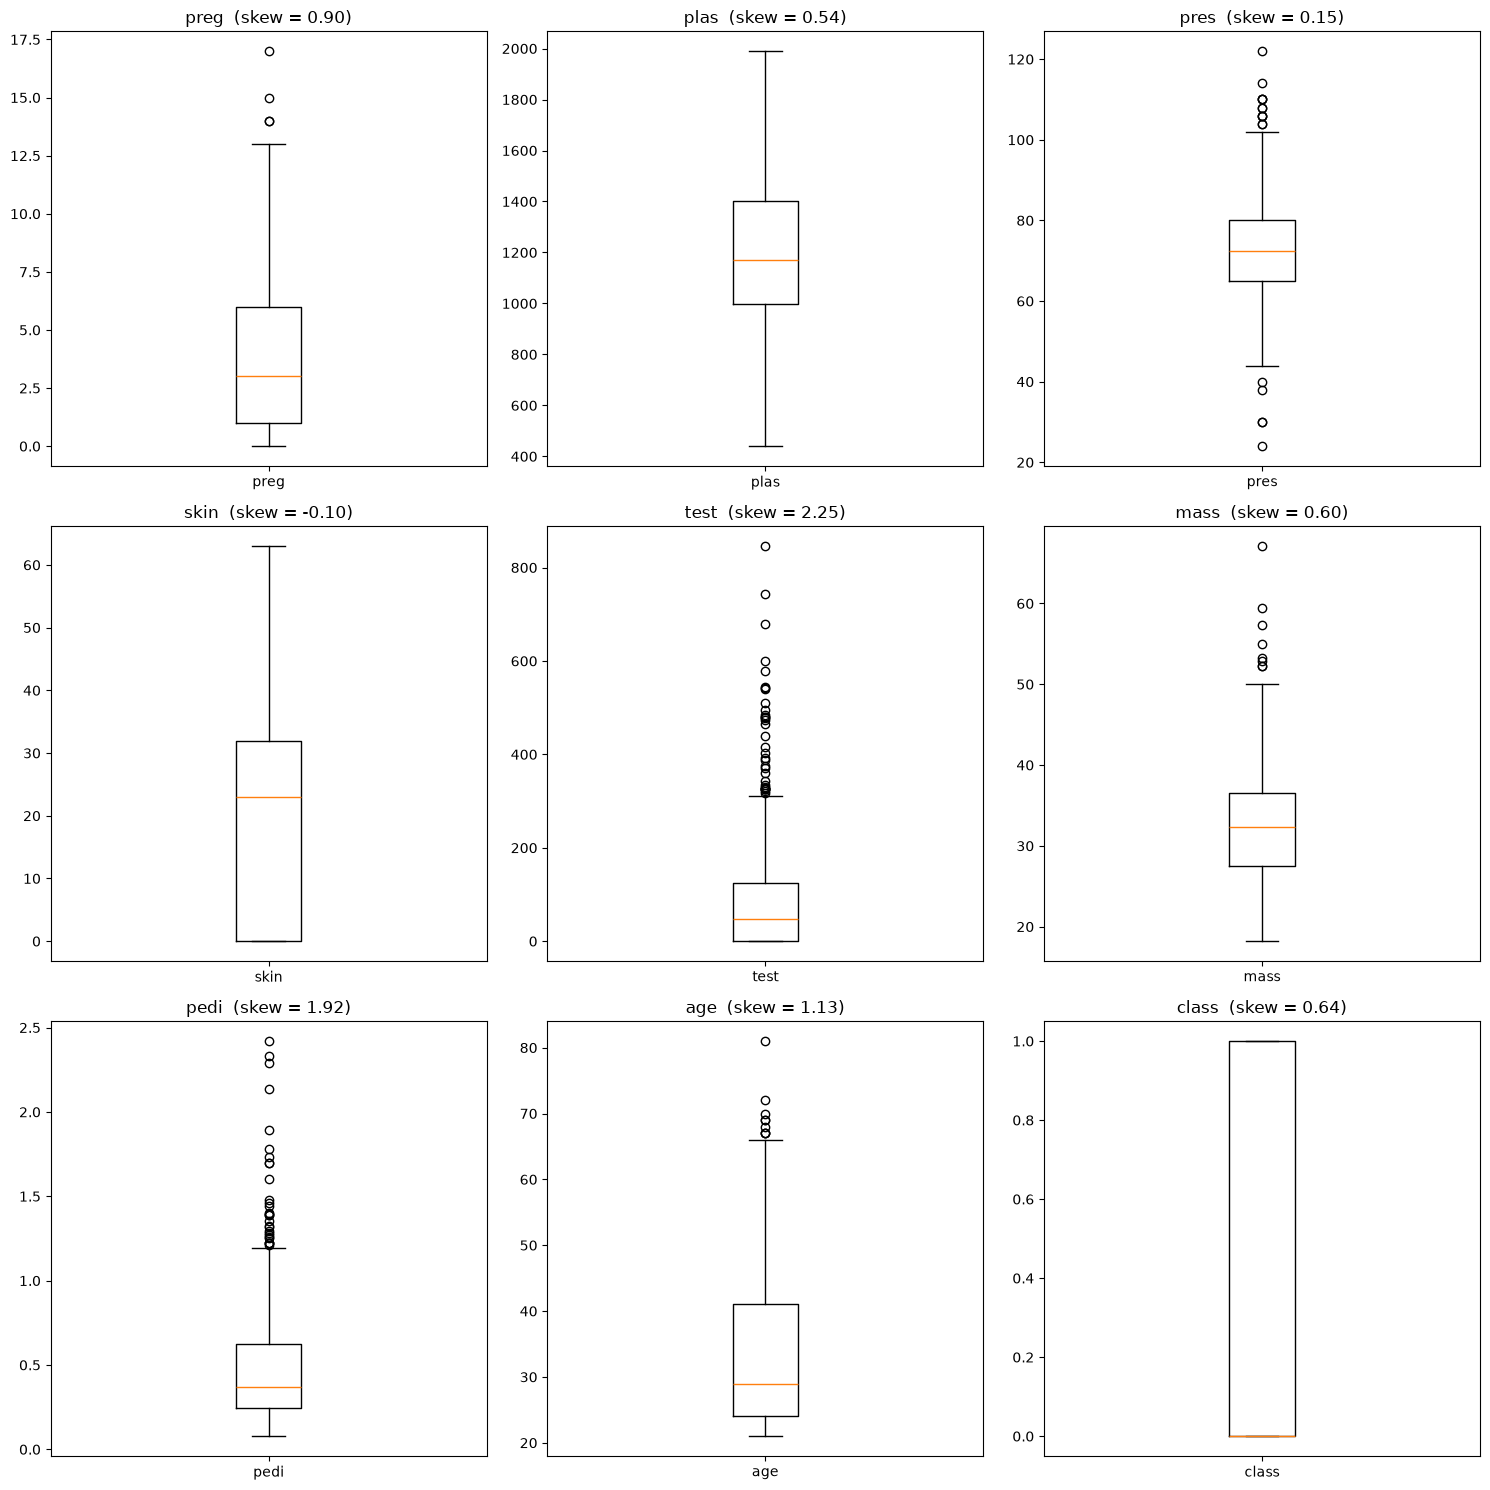

In [264]:
raw_df = raw_df.replace('?', np.nan) 
for col in ["pres", "skin", "test"]:
    raw_df[col] = pd.to_numeric(raw_df[col])
print(raw_df['plas'].describe())
print('--------------------------')
print(df['plas'].describe())

fig, axes = plt.subplots(3, 3, figsize=(15, 15))

for ax, col in zip(axes.flatten(), df.columns):
    ax.boxplot(df[col].dropna())
    ax.set_title(f"{col}  (skew = {df[col].skew():.2f})")
    ax.set_xticklabels([col])

plt.tight_layout()
plt.show()

## Reflection Questions
- 1. The columns that had missing values were 'pres', 'skin', and 'test', each having 38 missing values represented using '?'. 'pres' and 'skin' were imputed using mean imputation because they both have symmetrical distribution with skews of 0.14 and 0.17 respectively. 'test', 'plas', and 'mass' were imputed using median imputation because they were skewed and using mean would make the imputed values artificially high. For the columns 'pres', 'skin', 'test', 'plas', and 'mass', the zeroes were treated as missing values for the particular reason that these attributes cannot be zero in the real world. 'pres' represent diastolic blood pressure; 'skin' represents triceps skinfold thickness; 'test' represents a two-hour serum insulin test; 'plas' represents plasma glucose; 'mass' represents body mass index.  
All of these features cannot have a value of zero, hence, why the zeroes in these columns were treated as missing values. Because of this, the zeroes were also converted to NaN to not include the in the calculation of the skewness of the features. For instance, before converting the zeroes to NaN, 'pres' which represents blood pressure was negatively skewed. Blood pressure is usually approximately normal because it is determined by the cumulative effect of hundreds of independent genetic, environmental, and physiological variables balancing each other out across a population. The reason why it was negatively skewed here was because of the number of zeroes in the readings that represent missing values which significantly drags the tail to the left.   
'skin' which contained triceps skinfold thickness could also no be zero as it is not possible for a living human being. The skinfold measurement represents a double fold of skin and the underlying subcutaneous fat tissue. And even in individuals with severe malnutrition or extremely low body fat, human skin itself has a measurable thickness, meaning the value will always be greater than zero (typically a minimum of several millimeters).   
'test' representing a two-hour serum insulin test maintained its natural behaviour of being positively skewed because when looking at the general population, while most people cluster around a lower, baseline level of insulin, a smaller subset of the population stretches out into a long tail of exceptionally high values. Three out of the five columns ('pres', 'plas', 'mass') had their zeroes replaced by the imputed statistic, while the other two ('skin' and 'test') had their zeroes left as is because their zeroes occupied a significant amount of their cells, from about a third to half of the entire columns.